In [1]:
# Runtime evidence: this cell checks the environment actually used by the kernel.
import sys as _shape_sys, json as _shape_json, importlib.util as _shape_util
print("SHAPE_RUNTIME_PROVENANCE=" + _shape_json.dumps({
    "python_executable": _shape_sys.executable,
    "python_version": _shape_sys.version.split()[0],
    "shape_lab_origin": _shape_util.find_spec("shape_lab").origin
}))
del _shape_sys, _shape_json, _shape_util


SHAPE_RUNTIME_PROVENANCE={"python_executable": "/opt/pyvenv/bin/python", "python_version": "3.13.5", "shape_lab_origin": "/tmp/shape-course-nnkbpyws/course/src/shape_lab/__init__.py"}


# R02 — Projections, characteristic functions, and SIGReg

Read the single primary lesson before this lab. Predict each result. Numerical correctness is not independent mastery. See `representations/SOURCE_AUDIT.md` for provenance.

In [2]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'src/shape_lab').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook within the extracted course project.')
sys.path.insert(0, str(ROOT / 'src'))
from shape_lab import representations as r
from shape_lab import representation_experiments as exp
print('Course source:', ROOT)


Course source: /tmp/shape-course-nnkbpyws/course


## Calculate a characteristic function using only trigonometric averages.

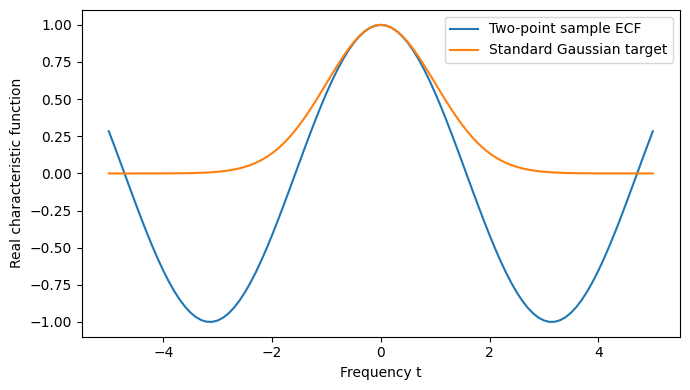

In [3]:
t = np.linspace(-5,5,101)
cf = r.empirical_cf(np.array([-1.,1.]), t)
assert np.allclose(cf.real, np.cos(t)) and np.allclose(cf.imag, 0)
plt.figure(figsize=(7,4)); plt.plot(t, cf.real, label='Two-point sample ECF'); plt.plot(t,np.exp(-t*t/2),label='Standard Gaussian target'); plt.xlabel('Frequency t'); plt.ylabel('Real characteristic function'); plt.legend(); plt.tight_layout(); plt.show()

## Compare a numerical integral with a separate analytic formula.

In [4]:
result = exp.projection_lab()
print(json.dumps(result, indent=2))
assert abs(result['quadrature']['1025']-result['exact_integral']) < 1e-8
assert result['flat_second_axis'] > result['flat_first_axis']

{
  "manufactured_controls": true,
  "exact_integral": 0.7472058553043581,
  "quadrature": {
    "17": 0.9265874148547769,
    "65": 0.7472058553043583,
    "257": 0.7472058553043583,
    "1025": 0.7472058553043586
  },
  "flat_first_axis": 1.3032128573863067,
  "flat_second_axis": 104.68370437489199,
  "seed_scores": {
    "0": 3.9178343127070687,
    "1": 3.0670655161721685,
    "2": 3.118834627063907,
    "3": 3.2029740637918547
  },
  "interpretation": "Quadrature, slice selection and sample variation are separate errors; none of these scores is a p-value.",
  "real_digits_pca": {
    "n": 1077,
    "dimension": 8,
    "mean_norm": 8.114179737808513e-17,
    "mean_coordinate_std": 0.6103773912499599,
    "covariance_identity_frobenius": 1.7945465105581186,
    "effective_rank": 7.0837876783380205
  },
  "real_digits_sample_count": 1077
}


## Treat projection seed as an experimental variable, not an unrecorded implementation detail.

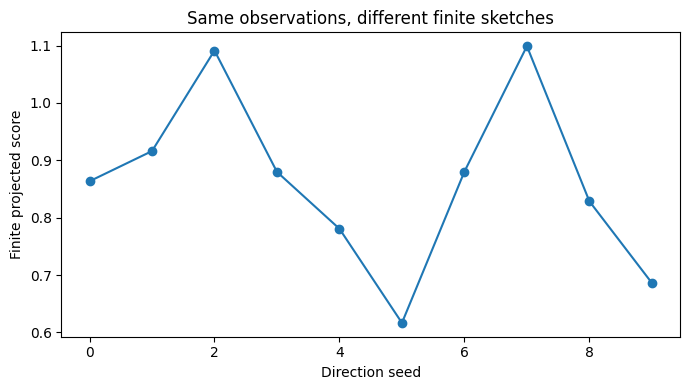

In [5]:
rng=np.random.default_rng(5); z=rng.normal(size=(64,8))
values=[r.projected_gaussian_score(z,r.unit_directions(8,16,s)) for s in range(10)]
plt.figure(figsize=(7,4)); plt.plot(range(10),values,marker='o'); plt.xlabel('Direction seed'); plt.ylabel('Finite projected score'); plt.title('Same observations, different finite sketches'); plt.tight_layout(); plt.show()

## Your evidence
Record: observation unit; assumptions; prediction; calculated result; difference from your prediction; and one unsupported conclusion. Attempt the separate learner notebook before opening the reference solutions.